## Ejercicio 9

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [44]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [45]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [46]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [47]:
def matriz_diferencias(n):
    # Guardamos por separado las diferencias entre vecinos horizontales y verticales.
    filas_h = []
    filas_v = []

    # k es la posición del píxel (i, j) en el vector de la imagen.
    # El -1 y el 1 permiten restarle ese píxel a su vecino de la derecha.
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + 1] = 1
            filas_h.append(fila)

    # Repetimos el procedimiento con el vecino de abajo, ubicado en k + n.
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + n] = 1
            filas_v.append(fila)

    # Unimos ambas listas: primero las diferencias horizontales y después las verticales.
    return np.array(filas_h + filas_v, dtype=float)


In [48]:
# Construimos D y comprobamos que cada fila compare solamente dos píxeles.
# axis=1 indica que contamos los valores en cada fila de la matriz.
D = matriz_diferencias(n)
print("Dimensiones de D:", D.shape)
print("¿Cada fila tiene un -1?", np.all(np.sum(D == -1, axis=1) == 1))
print("¿Cada fila tiene un 1?", np.all(np.sum(D == 1, axis=1) == 1))

# Los assert verifican las dimensiones y la cantidad de valores no nulos por fila.
assert D.shape == (112, 64)
assert np.all(np.sum(D == -1, axis=1) == 1)
assert np.all(np.sum(D == 1, axis=1) == 1)
assert np.all(np.count_nonzero(D, axis=1) == 2)

# Verificamos que D @ x_fantoma coincida con las diferencias calculadas con np.diff.
# Las primeras 56 son horizontales (axis=1) y las últimas 56, verticales (axis=0).
Dx = D @ x_fantoma
assert np.allclose(Dx[:n*(n-1)], np.diff(X_fantoma, axis=1).reshape(-1))
assert np.allclose(Dx[n*(n-1):], np.diff(X_fantoma, axis=0).reshape(-1))


Dimensiones de D: (112, 64)
¿Cada fila tiene un -1? True
¿Cada fila tiene un 1? True


### Inciso b)

In [49]:
# Una imagen de unos es constante: todos sus píxeles tienen el mismo valor.
x_constante = np.ones(n**2)

# Comparamos las diferencias entre vecinos: en la imagen constante son cero.
# En el fantoma la norma es positiva porque hay cambios entre algunos píxeles.
print("Norma de D @ x_constante:", np.linalg.norm(D @ x_constante))
print("Norma de D @ x_fantoma:", np.linalg.norm(D @ x_fantoma))
assert np.allclose(D @ x_constante, 0)


Norma de D @ x_constante: 0.0
Norma de D @ x_fantoma: 2.7055498516937364


En una imagen constante, todos los vecinos tienen el mismo valor. Cada fila de `D` resta
dos valores iguales, por eso todas las diferencias son cero. El fantoma tiene bordes y
cambios de atenuación: su norma de diferencias es aproximadamente 2,706.

### Inciso c)

El costo es

$$J_{\sigma,\lambda}(x)=\frac12\|A_7x-b_\sigma\|^2+
\frac\lambda2\|Dx\|^2.$$

El primer término mide la fidelidad a las mediciones. El segundo penaliza los cambios
entre píxeles vecinos. En particular,

$$\|Dx\|^2=\sum_{i=0}^{n-1}\sum_{j=0}^{n-2}(X_{i,j+1}-X_{ij})^2+
\sum_{i=0}^{n-2}\sum_{j=0}^{n-1}(X_{i+1,j}-X_{ij})^2.$$

La norma $\|Dx\|$ mide la variación total en sentido cuadrático, no la amplitud absoluta
de la imagen: sumar una constante no cambia sus diferencias. Con $\lambda=0$ obtenemos
mínimos cuadrados. Al aumentar $\lambda$, damos más importancia a la suavidad, lo que
puede reducir ruido y también borrar bordes reales.

### Inciso d)

In [50]:
# Calculamos las mediciones sin ruido a partir del fantoma.
b7 = A7 @ x_fantoma

# La semilla 67 permite repetir el mismo ruido que usamos en el ejercicio 6.
rng = np.random.default_rng(67)
z = rng.standard_normal(b7.size)

# Esta escala adapta la intensidad del ruido al tamaño de las mediciones.
escala = np.sqrt(np.mean(b7**2))


In [51]:
# sigma controla el nivel de ruido y lambda, el peso de la regularización.
sigmas = [0.0, 0.10, 0.20]
lambdas = [0.0, 0.1, 0.3, 1.0]

# Guardamos las mediciones de cada sigma en un diccionario.
# Usamos el mismo vector z y cambiamos su intensidad. Con sigma=0 no agregamos ruido.
mediciones = {sigma: b7 + sigma * escala * z for sigma in sigmas}
print("Usamos la misma semilla 67 y el mismo vector z del ejercicio 6.")


Usamos la misma semilla 67 y el mismo vector z del ejercicio 6.


### Inciso e)

In [52]:
def gradiente_descendiente(A, b, alpha, max_iter=10000, tol=1e-8,
                          D=None, lam=0.0, x_ref=None):
    # Empezamos con una imagen de ceros y guardamos las transpuestas para reutilizarlas.
    # Si no se pasa D, dejamos DT en None porque no calcularemos regularización.
    x = np.zeros(A.shape[1], dtype=float)
    AT = A.T
    DT = None if D is None else D.T

    # Preparamos los historiales y los datos que usaremos para decidir cuándo parar.
    costos = []
    normas_gradiente = []
    errores = []
    norma_inicial = None
    motivo = "máximo de iteraciones"

    t = 0
    for t in range(max_iter + 1):
        # Calculamos el costo y el gradiente del ajuste a las mediciones.
        residuo = A @ x - b
        costo = 0.5 * np.dot(residuo, residuo)
        grad = AT @ residuo

        # Agregamos regularización solo si tenemos D y su peso no es cero.
        # Este término penaliza las diferencias entre píxeles vecinos.
        if D is not None and lam != 0:
            diferencias = D @ x
            costo += 0.5 * lam * np.dot(diferencias, diferencias)
            grad = grad + lam * (DT @ diferencias)

        norma_grad = np.linalg.norm(grad)
        # Guardamos la norma inicial solo en la primera vuelta para fijar la tolerancia.
        if norma_inicial is None:
            norma_inicial = norma_grad

        # Registramos el costo y la norma del gradiente antes de actualizar la imagen.
        costos.append(float(costo))
        normas_gradiente.append(float(norma_grad))

        # Si conocemos el fantoma, registramos el error relativo para comparaciones.
        # Esa referencia no interviene en el paso del método ni en su parada.
        if x_ref is not None:
            errores.append(np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref))

        # Frenamos si el costo es infinito, NaN o supera un límite práctico muy grande.
        # El límite 1e25 evita seguir con valores descontrolados; no es el mínimo buscado.
        if not np.isfinite(costo) or costo > 1e25:
            motivo = "costo divergente"
            break

        # Paramos cuando el gradiente es pequeño respecto de su norma inicial.
        # max(1.0, norma_inicial) evita exigir una tolerancia menor que tol si esa norma es menor que 1.
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break

        # Al llegar al máximo, salimos antes de hacer una actualización adicional.
        if t == max_iter:
            break

        # Actualizamos la imagen en la dirección opuesta al gradiente.
        x = x - alpha * grad

    # Devolvemos la reconstrucción, los historiales y el motivo de parada.
    return {"x": x, "costos": np.array(costos),
            "normas_gradiente": np.array(normas_gradiente),
            "errores": np.array(errores), "iteraciones": t, "motivo": motivo}


Reutilizamos la actualización de gradiente y agregamos $\lambda D^TDx$ al gradiente.
La función siempre comienza con $x_0=0$. El argumento `x_ref` permite registrar el error
del fantoma para los gráficos pero no participa de la actualización ni de la parada.

### Inciso f)

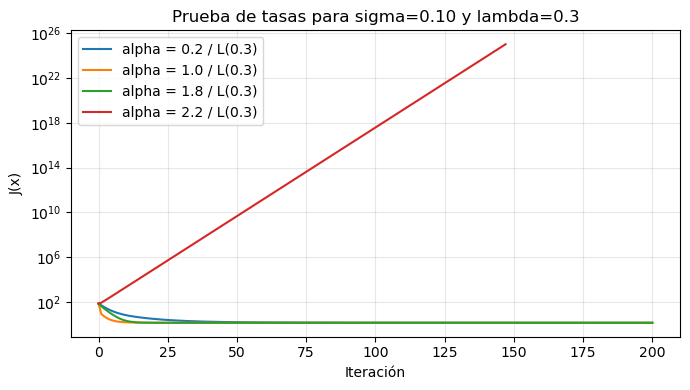

Tasa común elegida: 0.04934652837164658
Límite más restrictivo: 0.0548294759684962
Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones.



| sigma | lambda | Iteraciones | Motivo de parada |
| --- | --- | --- | --- |
| 0.0 | 0.0 | 522 | tolerancia del gradiente |
| 0.0 | 0.1 | 335 | tolerancia del gradiente |
| 0.0 | 0.3 | 199 | tolerancia del gradiente |
| 0.0 | 1.0 | 94 | tolerancia del gradiente |
| 0.1 | 0.0 | 549 | tolerancia del gradiente |
| 0.1 | 0.1 | 354 | tolerancia del gradiente |
| 0.1 | 0.3 | 212 | tolerancia del gradiente |
| 0.1 | 1.0 | 96 | tolerancia del gradiente |
| 0.2 | 0.0 | 565 | tolerancia del gradiente |
| 0.2 | 0.1 | 364 | tolerancia del gradiente |
| 0.2 | 0.3 | 219 | tolerancia del gradiente |
| 0.2 | 1.0 | 98 | tolerancia del gradiente |


In [53]:
from IPython.display import Markdown, display

# Calculamos la Hessiana para cada lambda y guardamos su mayor valor propio L.
# Estos valores permiten elegir una tasa de aprendizaje estable.
H = A7.T @ A7
DtD = D.T @ D
L_por_lambda = {}

for lam in lambdas:
    H_lambda = H + lam * DtD
    valores_propios = np.linalg.eigvalsh(H_lambda)
    L_por_lambda[lam] = valores_propios[-1]

L_max = max(L_por_lambda.values())

# Probamos distintas tasas para sigma=0.10 y lambda=0.3
factores = [0.2, 1.0, 1.8, 2.2]
fig, ax = plt.subplots(figsize=(7, 4))

for factor in factores:
    tasa = factor/L_por_lambda[0.3]
    prueba = gradiente_descendiente(A7, mediciones[0.1], tasa,
                                    max_iter=200, tol=1e-9, D=D, lam=0.3)
    etiqueta = "alpha = " + str(factor) + " / L(0.3)"
    ax.semilogy(prueba["costos"], label=etiqueta)

ax.set_xlabel("Iteración")
ax.set_ylabel("J(x)")
ax.set_title("Prueba de tasas para sigma=0.10 y lambda=0.3")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Elegimos una tasa común menor que 2/L_max para que sea estable en todos los casos.
alpha = 1.8/L_max
print("Tasa común elegida:", alpha)
print("Límite más restrictivo:", 2/L_max)
print("Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones.")
print()

# Reconstruimos la imagen para cada combinación de ruido y regularización.
# Guardamos cada resultado con la clave (sigma, lam) para usarlo en los próximos incisos.
tabla = "| sigma | lambda | Iteraciones | Motivo de parada |\n"
tabla += "| --- | --- | --- | --- |\n"
resultados = {}
for sigma in sigmas:
    for lam in lambdas:
        resultado = gradiente_descendiente(A7, mediciones[sigma], alpha,
                                           max_iter=10000, tol=1e-9,
                                           D=D, lam=lam, x_ref=x_fantoma)
        resultados[sigma, lam] = resultado
        # Agregamos una fila a la tabla con los datos de esta combinación.
        tabla += "| " + str(sigma) + " | " + str(lam) + " | "
        tabla += str(resultado["iteraciones"]) + " | " + resultado["motivo"] + " |\n"

# Mostramos la tabla con las doce combinaciones.
display(Markdown(tabla))


La Hessiana es $A_7^TA_7+\lambda D^TD$. Calculamos su mayor autovalor para elegir una
tasa menor que $2/L(\lambda)$ en todos los casos. La prueba con $2{,}2/L(0{,}3)$ muestra
la inestabilidad fuera del intervalo.

La parada exige $\|\nabla J(x_t)\|\leq10^{-9}\max(1,\|\nabla J(x_0)\|)$ o alcanzar
el máximo de iteraciones. No usamos el error respecto del fantoma para decidir cuándo parar.

### Inciso g)

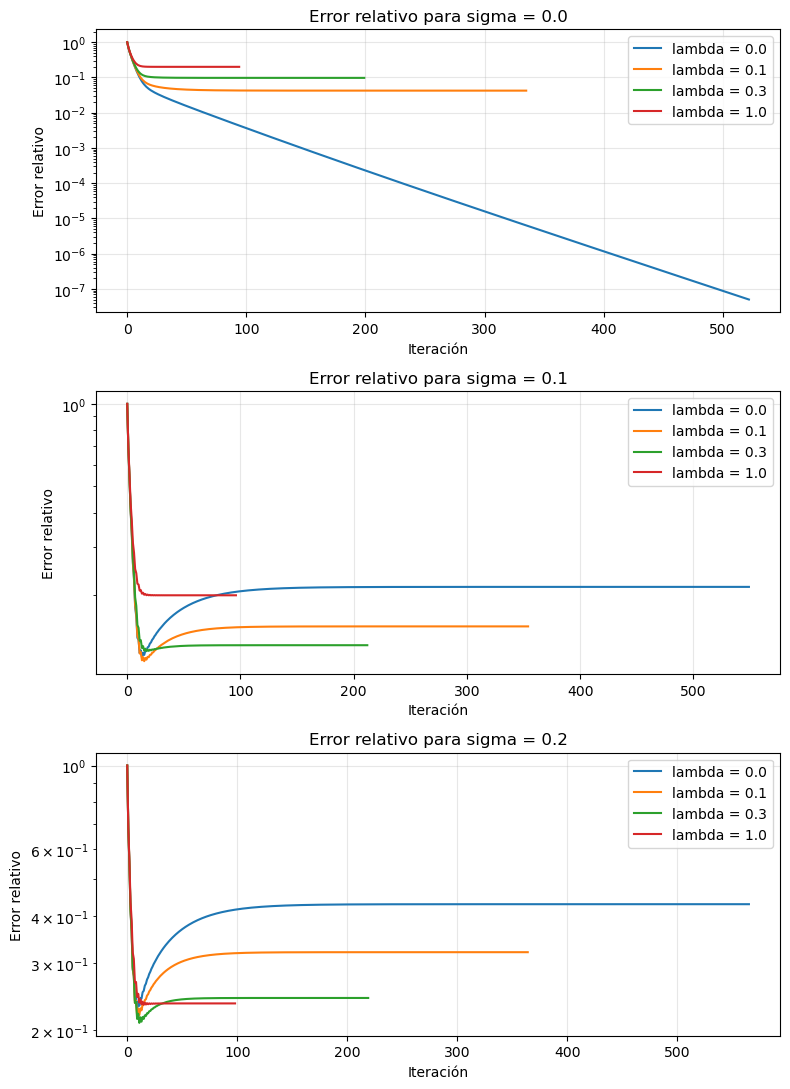

In [54]:
# Creamos un gráfico por nivel de ruido, uno debajo del otro.
fig, axs = plt.subplots(len(sigmas), 1, figsize=(8, 11))

for i in range(len(sigmas)):
    sigma = sigmas[i]

    # Comparamos cómo cambia el error relativo para cada valor de lambda.
    # La escala logarítmica permite distinguir los errores pequeños.
    for lam in lambdas:
        errores = resultados[sigma, lam]["errores"]
        etiqueta = "lambda = " + str(lam)
        axs[i].semilogy(errores, label=etiqueta)

    # Agregamos el nivel de ruido, los nombres de los ejes y la leyenda.
    axs[i].set_title("Error relativo para sigma = " + str(sigma))
    axs[i].set_xlabel("Iteración")
    axs[i].set_ylabel("Error relativo")
    axs[i].legend()
    axs[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Inciso h)

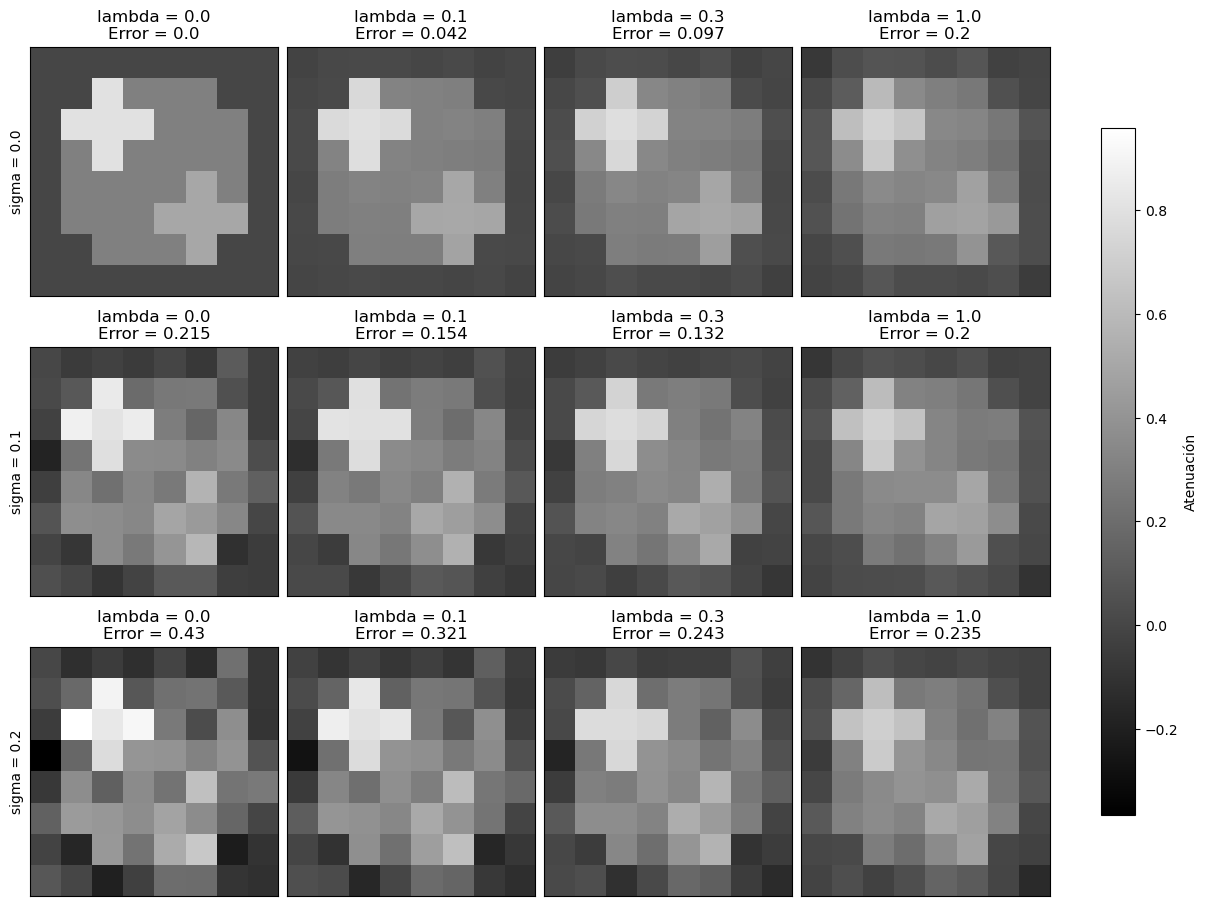

In [55]:
# Buscamos el menor y el mayor valor para usar la misma escala de grises en todas las imágenes.
vmin = 0.0
vmax = np.max(X_fantoma)

for sigma in sigmas:
    for lam in lambdas:
        x = resultados[sigma, lam]["x"]
        vmin = min(vmin, np.min(x))
        vmax = max(vmax, np.max(x))

# Cada fila corresponde a un nivel de ruido y cada columna a un valor de lambda.
fig, axs = plt.subplots(len(sigmas), len(lambdas), figsize=(12, 9), layout="constrained")

for i in range(len(sigmas)):
    sigma = sigmas[i]
    for j in range(len(lambdas)):
        lam = lambdas[j]

        # Recuperamos la reconstrucción y el último error relativo guardado.
        resultado = resultados[sigma, lam]
        imagen = resultado["x"].reshape(n, n)
        error = resultado["errores"][-1]

        # Mostramos la imagen e indicamos lambda y el error redondeado a tres decimales.
        axs[i, j].imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
        titulo = "lambda = " + str(lam) + "\nError = " + str(round(error, 3))
        axs[i, j].set_title(titulo)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])

        # Escribimos sigma solo en la primera columna para identificar cada fila.
        if j == 0:
            axs[i, j].set_ylabel("sigma = " + str(sigma))

# Agregamos una barra de color común a partir de la primera imagen.
fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()


### Inciso i)

sigma: 0.0 - Mejor lambda: 0.0
Error relativo: 5.011173978091994e-08

sigma: 0.1 - Mejor lambda: 0.3
Error relativo: 0.1316857810081075

sigma: 0.2 - Mejor lambda: 1.0
Error relativo: 0.23496623058385757



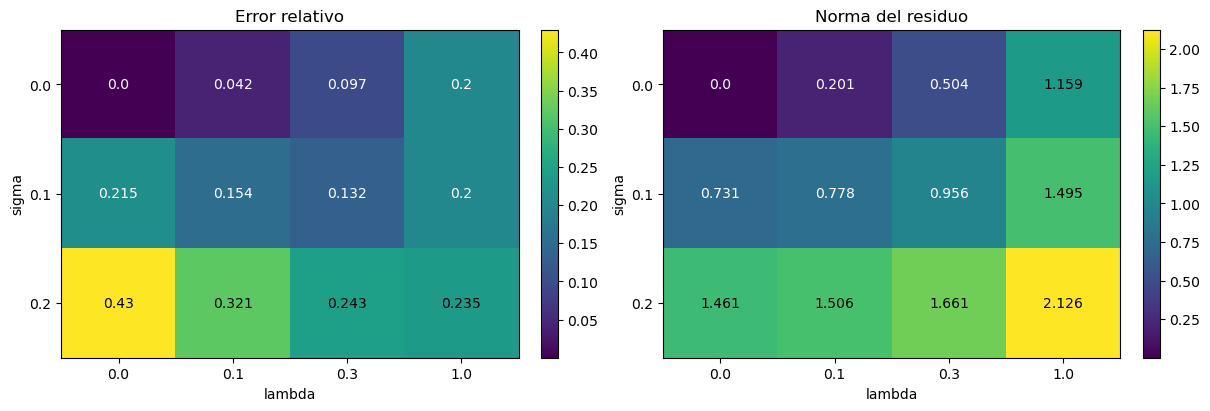

In [56]:
# Preparamos dos matrices: las filas representan sigma y las columnas, lambda.
errores_finales = np.zeros((len(sigmas), len(lambdas)))
residuos_finales = np.zeros((len(sigmas), len(lambdas)))
mejores = {}

for i in range(len(sigmas)):
    sigma = sigmas[i]
    for j in range(len(lambdas)):
        lam = lambdas[j]
        x = resultados[sigma, lam]["x"]

        # El error compara la reconstrucción con el fantoma.
        # El residuo compara las mediciones que produce esa imagen con las observadas.
        errores_finales[i, j] = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
        residuos_finales[i, j] = np.linalg.norm(A7 @ x - mediciones[sigma])

    # argmin devuelve la posición del menor error de esta fila.
    # Así elegimos el mejor lambda entre los valores que probamos para este sigma.
    indice = np.argmin(errores_finales[i])
    mejores[sigma] = lambdas[indice]
    print("sigma:", sigma, "- Mejor lambda:", mejores[sigma])
    print("Error relativo:", errores_finales[i, indice])
    print()

# Mostramos los errores y los residuos en dos cuadros de colores.
tablas = [errores_finales, residuos_finales]
titulos = ["Error relativo", "Norma del residuo"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for k in range(2):
    tabla = tablas[k]
    ax = axs[k]
    imagen = ax.imshow(tabla, cmap="viridis", aspect="auto")

    # Identificamos cada columna por su lambda y cada fila por su sigma.
    ax.set_xticks(range(len(lambdas)))
    ax.set_xticklabels(lambdas)
    ax.set_yticks(range(len(sigmas)))
    ax.set_yticklabels(sigmas)
    ax.set_xlabel("lambda")
    ax.set_ylabel("sigma")
    ax.set_title(titulos[k])

    # Escribimos los valores dentro de cada casillero, redondeados a tres decimales.
    # Elegimos texto blanco en los colores oscuros y negro en los claros para que se lea.
    punto_medio = (np.max(tabla) + np.min(tabla)) / 2
    for i in range(len(sigmas)):
        for j in range(len(lambdas)):
            if tabla[i, j] < punto_medio:
                color = "white"
            else:
                color = "black"
            valor = str(round(tabla[i, j], 3))
            ax.text(j, i, valor, ha="center", va="center", color=color)

    # Cada cuadro tiene su propia barra de color porque representan cantidades distintas.
    fig.colorbar(imagen, ax=ax)

plt.show()


### Inciso j)

Sin ruido, el mejor valor es $\lambda=0$: `A7` ya determina el fantoma y la regularización
agrega un sesgo de suavizado. Con $\lambda=1$ el error sin ruido sube aproximadamente a $0{,}200$.

Para $\sigma=0{,}10$, el mejor valor de los probados es $\lambda=0{,}3$: el error baja
de $0{,}189$ sin regularización a $0{,}151$. Con $\lambda=1$ vuelve a subir a $0{,}213$,
porque el suavizado borra detalles útiles.

Para $\sigma=0{,}20$, el mejor de los valores probados es $\lambda=1$, y el error baja
de $0{,}378$ a $0{,}256$. En esta experiencia conviene penalizar más cuando aumenta el ruido.
Eso no demuestra que el mejor valor posible sea exactamente uno: solamente es el mejor
de la grilla considerada.

La regularización permite aceptar un residuo mayor para obtener una imagen más cercana al
fantoma. Si la penalización es excesiva, los píxeles vecinos se igualan demasiado y se pierden
bordes y regiones pequeñas. Las curvas del error también muestran que un buen ajuste de
mediciones y una buena reconstrucción no siempre mejoran juntos.